# 23d · Longer context versus retrieved context

## The engineering question
Does supplying the complete small corpus improve answers enough to justify its token and latency cost?

**Learning outcomes:** compare the same generator and question across bounded contexts; measure position effects, evidence coverage, and answer signals; reject oversized input explicitly; separate tiny experiments from large-context model claims.

We use three approved development questions (warranty, reset, and unanswerable). Each sees retrieved evidence plus three arrangements of the complete authorized corpus: the principal answer source near the front, middle, or end. The same Qwen model, prompt, greedy decoding, and 96-token output cap apply. The course limit remains 2,048 total tokens. This is a small full-corpus comparison, not a 100K-token benchmark. [Long-context/RAG study](https://arxiv.org/abs/2407.16833v2).

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from vector_masterclass.lesson import LessonRun
from vector_masterclass.config import root

plt.rcParams.update(
    {"figure.figsize": (8, 4), "axes.spines.top": False, "axes.spines.right": False}
)
lesson = LessonRun("23d", "G", docker=True)
print("Kernel:", sys.executable)
print("Workspace:", root())

Kernel: /Users/markcastillo/git/vector-masterclass/.venv/bin/python3
Workspace: /Users/markcastillo/git/vector-masterclass


Oversize rejection: Prompt plus output budget exceeds the course context limit; pack evidence first


,query,condition,input_tokens,generation_seconds,evidence_coverage,required_fact_pattern_pass,cited_gold_span,exact_abstention,answer
0,d01,retrieved top 3,215,3.935975,1.0,True,True,False,The Atlas router's warranty covers it for two ...
1,d01,full corpus / front,985,1.851746,1.0,True,False,False,The Atlas router's warranty lasts two years fr...
2,d01,full corpus / middle,985,2.622681,1.0,True,True,False,The warranty on an Atlas router lasts two year...
3,d01,full corpus / end,985,1.302077,1.0,True,False,False,The warranty on an Atlas router lasts two year...
4,d02,retrieved top 3,230,3.530392,1.0,True,True,False,"Yes, an Atlas factory reset will preserve your..."
5,d02,full corpus / front,985,1.667911,1.0,True,True,False,"Yes, according to [E1], holding the recessed r..."
6,d02,full corpus / middle,985,2.833306,1.0,True,False,False,"Yes, an Atlas factory reset will preserve your..."
7,d02,full corpus / end,985,0.692875,1.0,False,False,True,Insufficient evidence.
8,d07,retrieved top 3,212,0.262833,NaN,None,None,True,Insufficient evidence.
9,d07,full corpus / front,982,0.687686,NaN,None,None,True,Insufficient evidence.


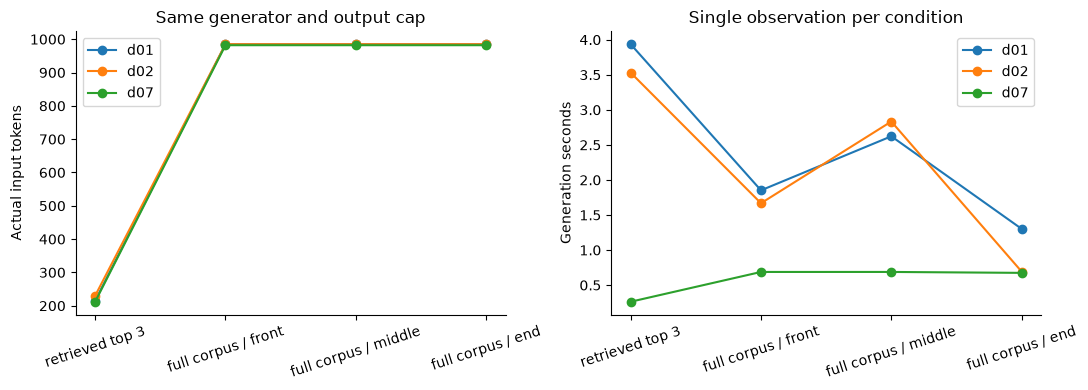

In [2]:
from uuid import uuid4
from transformers import AutoTokenizer
from vector_masterclass.config import model_path, model_config
from vector_masterclass.data import documents, queries
from vector_masterclass.chunking import chunk_document
from vector_masterclass.store import VectorIndex
from vector_masterclass.context import assemble
from vector_masterclass.models import release_models, generate
from vector_masterclass.rag import answer, score_answer
from vector_masterclass.metrics import evidence_coverage
from vector_masterclass.evidence import json_write

docs = documents(tenant="public")
qs = [q for q in queries("development") if q.id in {"d01", "d02", "d07"}]
tokenizer = AutoTokenizer.from_pretrained(str(model_path("generator")), local_files_only=True)
index = VectorIndex("vmc_23d_" + uuid4().hex[:8])
index.create()
prepared = []
try:
    for doc in docs:
        index.upsert(chunk_document(doc, "document"), document_id=doc.id, include_sparse=False)
    for q in qs:
        hits = index.search(q.text, tenant=q.tenant, mode="dense", k=3, exact=True)
        prepared.append(
            (
                q,
                "retrieved top 3",
                assemble([h.chunk for h in hits], docs, tokenizer, 384, tenant=q.tenant),
            )
        )
        target = next((d for d in docs if q.relevance.get(d.key, 0) > 0), docs[0])
        others = [d for d in docs if d != target]
        for position, insertion in [
            ("front", 0),
            ("middle", len(others) // 2),
            ("end", len(others)),
        ]:
            ordered = others.copy()
            ordered.insert(insertion, target)
            context = assemble(
                [chunk_document(d, "document")[0] for d in ordered],
                docs,
                tokenizer,
                1600,
                tenant=q.tenant,
            )
            assert len(context["chunks"]) == len(docs), (
                "Full-corpus condition must not silently truncate"
            )
            prepared.append((q, "full corpus / " + position, context))
finally:
    index.drop()
    index.close()
release_models()
rows = []
traces = []
for q, condition, context in prepared:
    generated = answer(q.text, context)
    traces.append(generated | {"condition": condition, "query_id": q.id})
    rows.append(
        score_answer(q, generated)
        | {
            "condition": condition,
            "evidence_tokens": context["tokens"],
            "evidence_coverage": evidence_coverage(context["chunks"], q.evidence)["coverage"],
        }
    )
oversized_rejected = False
try:
    generate("Evidence: " + ("irrelevant " * 3000), max_new_tokens=96)
except ValueError as error:
    oversized_rejected = "context limit" in str(error)
    print("Oversize rejection:", error)
results = lesson.table(pd.DataFrame(rows))
json_write(lesson.path / "generation-traces.json", traces)
display(
    results[
        [
            "query",
            "condition",
            "input_tokens",
            "generation_seconds",
            "evidence_coverage",
            "required_fact_pattern_pass",
            "cited_gold_span",
            "exact_abstention",
            "answer",
        ]
    ]
)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for qid, group in results.groupby("query"):
    axes[0].plot(group.condition, group.input_tokens, "o-", label=qid)
    axes[1].plot(group.condition, group.generation_seconds, "o-", label=qid)
axes[0].set(ylabel="Actual input tokens", title="Same generator and output cap")
axes[1].set(ylabel="Generation seconds", title="Single observation per condition")
for ax in axes:
    ax.tick_params(axis="x", rotation=18)
    ax.legend()
fig.tight_layout()
lesson.figure(fig)
plt.show()

## Interpretation and exercise
Read the complete answers: the required-fact regex can pass a contradictory answer, and a resolvable citation can be irrelevant. A full corpus removes this particular retrieval omission but retains distraction, attribution, stale-source, and generation risks. Position sensitivity on three questions is a diagnostic, not a statistical estimate. Decoding length and warmup confound single-call latency; report distributions before choosing a serving strategy.

Long-context access must still enforce authorization and current revisions before packing. Retrieval has index freshness and candidate-recall costs; full-corpus input has repeated token/prefill costs and a hard capacity limit. Neither replaces SQL for exact structured facts. Routing between them needs calibrated held-out outcomes and a fallback budget, not the model's unsupported confidence alone.

**Exercise:** manually score every claim in one question's four responses, then repeat under a fixed total token budget. Explain whether a changed answer originates in omitted evidence, position, decoding, or faulty evaluation. Design a larger holdout and randomized repeated latency study without tuning on this diagnostic set.

In [ ]:
manifest = lesson.finish(
    {
        "twelve_live_answers": len(traces) == 12 and all(t["live"] for t in traces),
        "oversized_prompt_rejected": oversized_rejected,
        "within_context_limit": bool(
            ((results.input_tokens + 96) <= model_config("generator")["max_length"]).all()
        ),
        "three_full_corpus_orders": results.condition.nunique() == 4,
        "full_corpus_more_tokens": float(
            results[results.condition.str.startswith("full")].input_tokens.mean()
        )
        > float(results[results.condition.eq("retrieved top 3")].input_tokens.mean()),
    },
    observations={
        "split": "development",
        "quality_scope": "required-fact and gold-span citation proxies; manual claim review required",
        "context_limit": 2048,
        "large_context_benchmark_reproduction": False,
    },
)

## References and next steps
Consult the [Qdrant documentation](https://qdrant.tech/documentation/),
the [MiniLM model card](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2),
and [uv's Jupyter guide](https://docs.astral.sh/uv/guides/integration/jupyter/).
The exact pinned configuration is in `configs/models.json`; worked exercises are in `docs/SOLUTIONS.md`.
This notebook's measurements apply to the recorded local run, not a production deployment.